# Non-Invasive Fetal ECG – Pre-processing

This notebook loads the NIFEA fetal ECG recording, visualizes the raw abdominal ECG, removes baseline wander and power-line/high-frequency noise, normalizes the signals, and applies Independent Component Analysis (ICA) for separation of the mixed ECG sources.

In [1]:
# If any package is missing in this notebook kernel, install it once:
!pip install numpy
!pip install matplotlib
!pip install scipy
!pip install scikit-learn
!pip install neurokit2
!pip install wfdb

# Import the libraries required for ECG loading, filtering, plotting and ICA
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
from sklearn.decomposition import FastICA
import neurokit2 as nk
import wfdb

# Set a fixed random seed so that results are reproducible
np.random.seed(0)

# Set the default figure size for ECG plots
plt.rcParams["figure.figsize"] = (12, 3)


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\07dee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\07dee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


...


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\07dee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\07dee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\07dee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Configuration

Set `USE_SYNTHETIC_DEMO = False` when working with the real NIFEA dataset.

In [2]:
# Choose between the artificial demonstration signal and the real NIFEA recording
USE_SYNTHETIC_DEMO = False

# Path to the recording WITHOUT the .dat or .hea extension
RECORD_PATH = r"C:\Users\07dee\OneDrive\Documents\Macroscopic_physiological system\non-invasive-fetal-ecg-arrhythmia-database-1.0.0\ARR_01"

# Sampling frequency used only for the synthetic demonstration
FS = 1000


## Loading synthetic data

This section creates an artificial ECG mixture only for testing the pipeline. It is not used when `USE_SYNTHETIC_DEMO = False`.

In [3]:
def load_synthetic_demo(fs=FS, duration=30):
    # Create the time axis for the artificial ECG signal
    t = np.linspace(0, duration, fs * duration)

    def make_pulses(t, hr_bpm, amp, width=0.02):
        # Create artificial heartbeat pulses using Gaussian-shaped peaks
        period = 60.0 / hr_bpm
        pulses = np.zeros_like(t)
        for pt in np.arange(0, t[-1], period):
            pulses += amp * np.exp(-0.5 * ((t - pt) / width) ** 2)
        return pulses

    # Create an artificial maternal ECG signal
    maternal = make_pulses(t, hr_bpm=75, amp=1.0)

    # Create an artificial fetal ECG signal with a higher heart rate
    fetal = make_pulses(t, hr_bpm=140, amp=0.15)

    # Create artificial baseline-wander noise
    baseline_wander = 0.3 * np.sin(2 * np.pi * 0.2 * t)

    # Create artificial 50 Hz power-line interference
    powerline = 0.05 * np.sin(2 * np.pi * 50 * t)

    # Create multiple abdominal signals by mixing maternal and fetal ECG with noise
    abdomen = []
    for _ in range(5):
        a, b = np.random.uniform(0.6, 1.0), np.random.uniform(0.3, 1.0)
        noise = 0.02 * np.random.randn(len(t))
        abdomen.append(a * maternal + b * fetal + baseline_wander + powerline + noise)
    abdomen = np.array(abdomen)

    # Create an artificial chest signal containing mainly maternal ECG
    chest = maternal + 0.5 * baseline_wander + 0.3 * powerline + 0.02 * np.random.randn(len(t))

    return t, chest, abdomen


## Loading actual data

The `.hea` file provides the recording metadata and the `.dat` file contains the signal samples. WFDB reads the two files together.

In [4]:
if USE_SYNTHETIC_DEMO:
    # Load the artificial signal for pipeline testing
    t, maternal_chest_raw, abdomen_raw = load_synthetic_demo()
    fs = FS
    sig_names = ["ECG"] + [f"Abdomen{i+1}" for i in range(abdomen_raw.shape[0])]
    print("Loaded SYNTHETIC demo signal.")
else:
    # Load the real NIFEA recording using its .hea and .dat files
    record = wfdb.rdrecord(RECORD_PATH)
    fs = record.fs
    sig_names = record.sig_name
    print("Channels found:", sig_names, "| Sampling rate:", fs)

    # Find the maternal ECG channel and all abdominal ECG channels
    chest_idx = sig_names.index("ECG")
    abdomen_idx = [i for i, name in enumerate(sig_names) if name.startswith("Abdomen")]

    # Extract the maternal chest ECG as a one-dimensional signal
    maternal_chest_raw = record.p_signal[:, chest_idx]

    # Extract abdominal channels and arrange them as channels x samples
    abdomen_raw = record.p_signal[:, abdomen_idx].T

    # Create the time axis in seconds
    t = np.arange(len(maternal_chest_raw)) / fs

# Display basic information about the loaded abdominal signals
print("Number of abdominal channels:", abdomen_raw.shape[0])
print("Number of samples per channel:", abdomen_raw.shape[1])
print("Sampling frequency:", fs, "Hz")


Channels found: ['ECG', 'Abdomen_1', 'Abdomen_2', 'Abdomen_3', 'Abdomen_4', 'Abdomen_5'] | Sampling rate: 1000
Number of abdominal channels: 5
Number of samples per channel: 600052
Sampling frequency: 1000 Hz


## Visualizing the raw abdominal ECG

The raw signal is plotted before preprocessing so that the effect of filtering can be compared later.

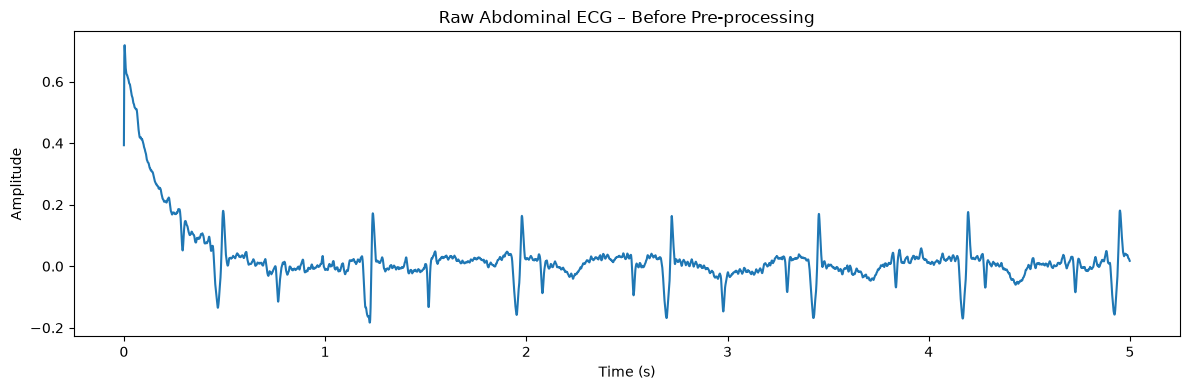

In [5]:
# Plot the first abdominal channel before any preprocessing
plt.figure(figsize=(12, 4))
plt.plot(t[:5000], abdomen_raw[0][:5000])
plt.title("Raw Abdominal ECG – Before Pre-processing")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()


## Removal of noises

Three filters are used in sequence:

1. **High-pass filter** – reduces slow baseline wander.
2. **Notch filter** – removes narrow-band 50 Hz power-line interference.
3. **Band-pass filter** – keeps the useful ECG frequency range while reducing very low and very high frequency noise.

In [6]:
# Baseline noise removal using a high-pass Butterworth filter
def highpass_filter(x, fs, cutoff=0.5, order=4):
    # Design a high-pass filter with a 0.5 Hz cutoff frequency
    b, a = sig.butter(order, cutoff / (fs / 2), btype="high")
    # Apply zero-phase filtering so that the ECG peaks are not shifted in time
    return sig.filtfilt(b, a, x)

# Apply the high-pass filter to every abdominal channel
abdomen_hp = np.array([highpass_filter(ch, fs) for ch in abdomen_raw])

# Remove narrow-band 50 Hz power-line noise using a notch filter
def notch_filter(x, fs, freq=50, quality=30):
    # Design a narrow notch centered at the power-line frequency
    b, a = sig.iirnotch(freq / (fs / 2), quality)
    # Apply zero-phase filtering to preserve the timing of ECG features
    return sig.filtfilt(b, a, x)

# Apply the notch filter to the high-pass filtered signals
abdomen_notch = np.array([notch_filter(ch, fs) for ch in abdomen_hp])

# Remove very low and very high frequency noise using a band-pass filter
def bandpass_filter(x, fs, low=3, high=45, order=4):
    # Design a Butterworth band-pass filter from 3 to 45 Hz
    b, a = sig.butter(order, [low / (fs / 2), high / (fs / 2)], btype="band")
    # Apply zero-phase filtering to preserve ECG waveform timing
    return sig.filtfilt(b, a, x)

# Apply the band-pass filter to obtain the final cleaned abdominal signals
abdomen_clean = np.array([bandpass_filter(ch, fs) for ch in abdomen_notch])

print("Pre-processing completed.")
print("Cleaned signal shape:", abdomen_clean.shape)


Pre-processing completed.
Cleaned signal shape: (5, 600052)


## Before and after filtering plot

This comparison shows the first abdominal channel before filtering and after all three filters have been applied.

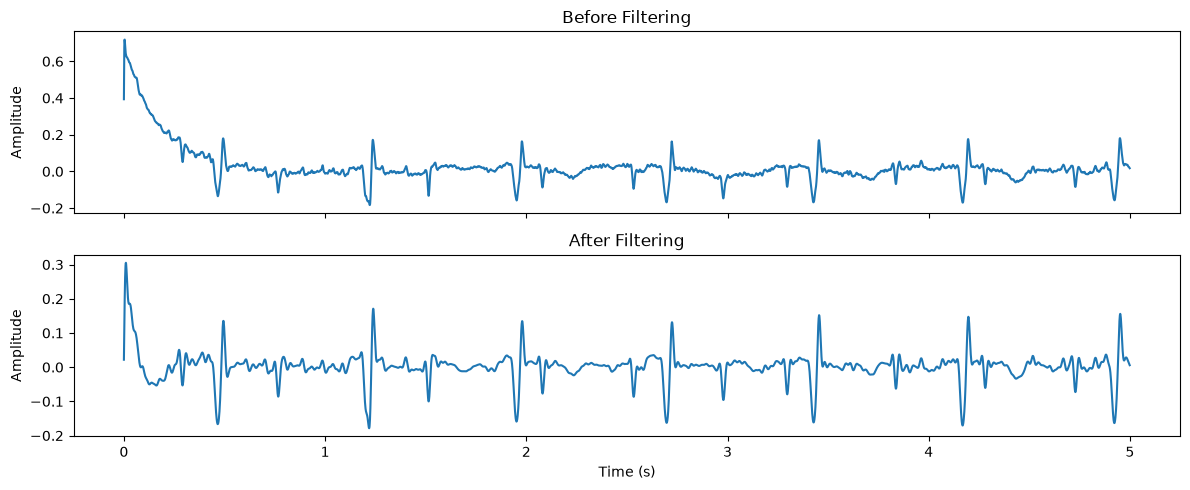

In [7]:
# Create two vertically stacked plots for direct comparison
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

# Plot the original abdominal ECG signal
axes[0].plot(t[:5000], abdomen_raw[0][:5000])
axes[0].set_title("Before Filtering")
axes[0].set_ylabel("Amplitude")

# Plot the signal after high-pass, notch and band-pass filtering
axes[1].plot(t[:5000], abdomen_clean[0][:5000])
axes[1].set_title("After Filtering")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Time (s)")

# Adjust the spacing between the two plots
plt.tight_layout()
plt.show()


## Normalization of the signals

Z-score normalization puts each abdominal channel on a comparable scale by subtracting its mean and dividing by its standard deviation. This is useful before ICA because ICA is sensitive to differences in signal scale.

In [8]:
def zscore(x):
    # Standardize the signal to zero mean and unit standard deviation
    return (x - np.mean(x)) / np.std(x)

# Normalize every cleaned abdominal channel independently
abdomen_norm = np.array([zscore(ch) for ch in abdomen_clean])

print("Normalized signal shape:", abdomen_norm.shape)


Normalized signal shape: (5, 600052)


## Plot of normalized abdominal signals

The normalized channels are displayed to confirm that they are on a comparable amplitude scale before ICA.

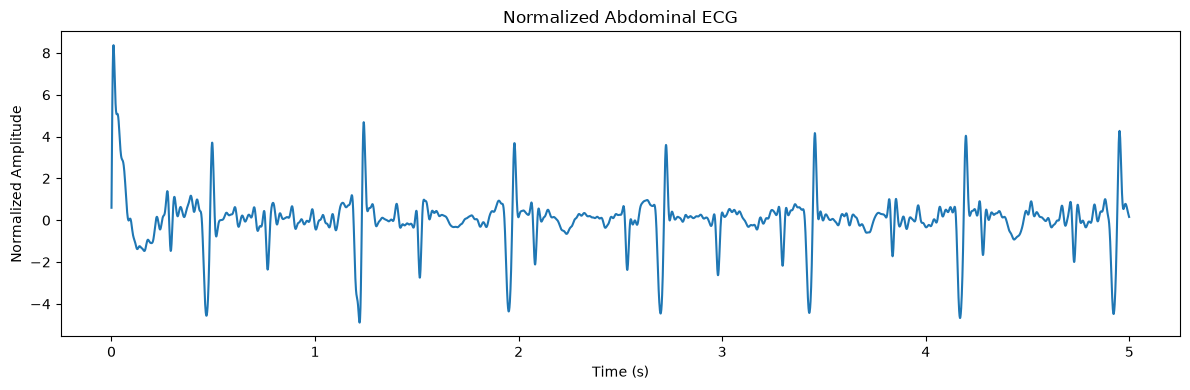

In [9]:
# Plot the first normalized abdominal channel
plt.figure(figsize=(12, 4))
plt.plot(t[:5000], abdomen_norm[0][:5000])
plt.title("Normalized Abdominal ECG")
plt.xlabel("Time (s)")
plt.ylabel("Normalized Amplitude")
plt.tight_layout()
plt.show()


## Fetal signal separation from mixed abdominal signals using ICA

The abdominal ECG contains a mixture of maternal ECG, fetal ECG and other components. ICA attempts to separate these mixed signals into statistically independent components.

**Important:** ICA does not automatically label a component as fetal ECG. The resulting components must be inspected and the fetal component identified using ECG characteristics such as fetal heart-rate/R-peak patterns.

In [10]:
# Create the ICA model using one component for each abdominal channel
ica = FastICA(
    n_components=abdomen_norm.shape[0],
    random_state=0,
    max_iter=1000,
    whiten="unit-variance"
)

# FastICA expects data in the form: samples x channels, so transpose the signal matrix
sources = ica.fit_transform(abdomen_norm.T).T

print("ICA completed.")
print("Number of independent components:", sources.shape[0])
print("Samples per component:", sources.shape[1])


ICA completed.
Number of independent components: 5
Samples per component: 600052


## Visualizing ICA components

Each subplot represents one independent component obtained from the mixed abdominal ECG signals. These components can be inspected to identify the maternal, fetal and artifact-related signals.

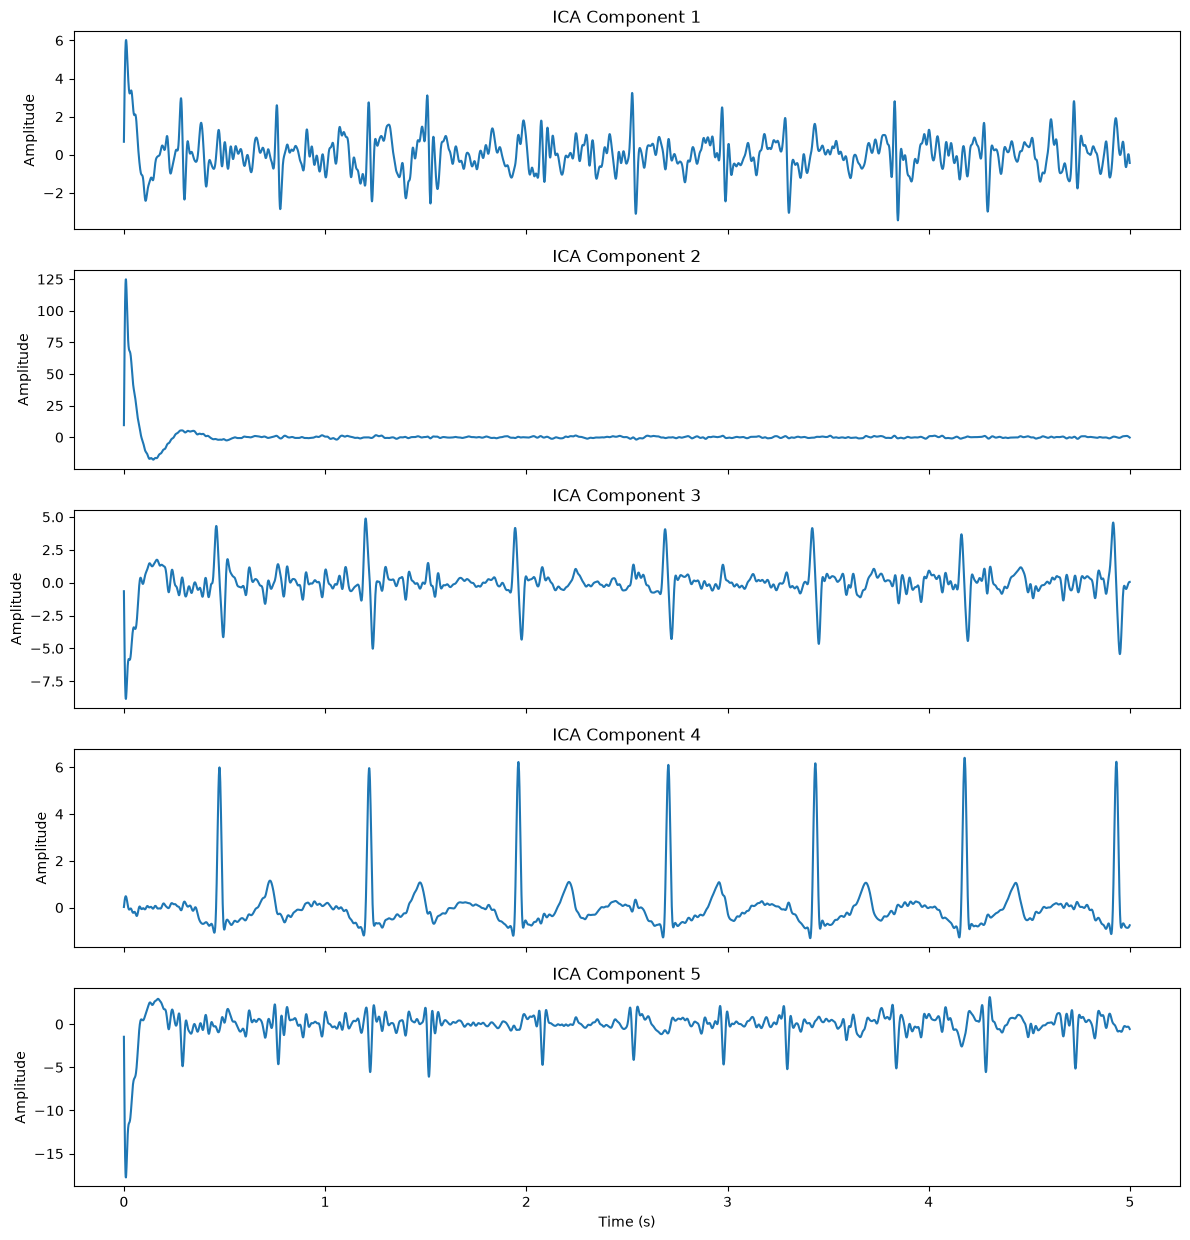

In [11]:
# Create one subplot for every independent component
n_components = sources.shape[0]
fig, axes = plt.subplots(n_components, 1, figsize=(12, 2.5 * n_components), sharex=True)

# Convert the single-axis case into an array so the loop works for any number of components
axes = np.atleast_1d(axes)

# Plot each independent component
for i, ax in enumerate(axes):
    ax.plot(t[:5000], sources[i][:5000])
    ax.set_title(f"ICA Component {i + 1}")
    ax.set_ylabel("Amplitude")

# Label the shared time axis on the last subplot
axes[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()


## Pre-processing pipeline summary

**Raw abdominal ECG → High-pass filtering → 50 Hz notch filtering → Band-pass filtering → Normalization → ICA → Independent components**

The fetal ECG component can be selected and processed further in the fetal ECG extraction and feature-extraction stage.

## Batch Pre-processing — Running the Pipeline on Every Recording

The steps above were built and verified on a single recording (`ARR_01`). Independent Component
Analysis, filtering, and normalization now need to run the same way on **every** recording in the
dataset (all `ARR_xx` and `NR_xx` files), not just one.

Rather than repeating all the cells above by hand for each file, the exact same steps are wrapped
into a single function, `preprocess_recording()`, which is then looped automatically over every
`.hea` file found in the dataset folder.

In [12]:
import glob
import os

def preprocess_recording(record_path):
    """Runs the full tested pre-processing pipeline (load -> filter -> normalize -> ICA)
    on a single recording. Returns the ICA sources and normalized signal, or None if the
    recording fails to process (so the batch loop can skip it and continue)."""
    try:
        # Load the recording using its .hea and .dat files
        record = wfdb.rdrecord(record_path)
        fs = record.fs
        sig_names = record.sig_name

        # Identify the maternal chest channel and all abdominal channels
        chest_idx = sig_names.index("ECG")
        abdomen_idx = [i for i, name in enumerate(sig_names) if name.startswith("Abdomen")]

        maternal_chest_raw = record.p_signal[:, chest_idx]
        abdomen_raw = record.p_signal[:, abdomen_idx].T

        # Apply the same three filters, in the same order, as the single-file pipeline above
        abdomen_hp = np.array([highpass_filter(ch, fs) for ch in abdomen_raw])
        abdomen_notch = np.array([notch_filter(ch, fs) for ch in abdomen_hp])
        abdomen_clean = np.array([bandpass_filter(ch, fs) for ch in abdomen_notch])

        # Normalize every cleaned abdominal channel
        abdomen_norm = np.array([zscore(ch) for ch in abdomen_clean])

        # Separate the mixed abdominal signals into independent components using ICA
        ica = FastICA(n_components=abdomen_norm.shape[0], random_state=0,
        max_iter=1000, whiten="unit-variance")
        sources = ica.fit_transform(abdomen_norm.T).T

        # Use the filename itself to identify the recording (e.g. "ARR_01", "NR_07")
        record_id = os.path.basename(record_path)

        return {
            "record_id": record_id,
            "fs": fs,
            "abdomen_norm": abdomen_norm,
            "sources": sources,
        }

    except Exception as e:
        # Print which file failed and why, then let the batch loop continue with the rest
        print(f"FAILED on {record_path}: {e}")
        return None

### Discover and process every recording in the dataset folder

`glob` automatically finds every `.hea` file in the dataset folder, so every `ARR_xx` and `NR_xx`
recording is picked up without typing out 26 filenames by hand. `preprocess_recording()` is then
called once per file, and the results are collected into a single list.

In [13]:
# Folder containing all downloaded NIFEA DB recordings (.dat + .hea pairs)
DATA_DIR = r"C:\Users\07dee\OneDrive\Documents\Macroscopic_physiological system\non-invasive-fetal-ecg-arrhythmia-database-1.0.0"

# Find every recording by locating its .hea file, then strip the extension
# (wfdb expects the record path WITHOUT .dat or .hea)
hea_files = glob.glob(os.path.join(DATA_DIR, "*.hea"))
record_paths = sorted([f[:-4] for f in hea_files])

print(f"Found {len(record_paths)} recordings in the dataset folder.")

# Run the pre-processing pipeline on every recording, one at a time
all_results = []
for rp in record_paths:
    print(f"Preprocessing {os.path.basename(rp)} ...")
    result = preprocess_recording(rp)
    if result is not None:
        all_results.append(result)

print(f"\nDone. Successfully preprocessed {len(all_results)} / {len(record_paths)} recordings.")

Found 26 recordings in the dataset folder.
Preprocessing ARR_01 ...
Preprocessing ARR_02 ...
Preprocessing ARR_03 ...
Preprocessing ARR_04 ...
Preprocessing ARR_05 ...
Preprocessing ARR_06 ...
Preprocessing ARR_07 ...
Preprocessing ARR_08 ...
Preprocessing ARR_09 ...
Preprocessing ARR_10 ...
Preprocessing ARR_11 ...
Preprocessing ARR_12 ...
Preprocessing NR_01 ...
Preprocessing NR_02 ...
Preprocessing NR_03 ...
Preprocessing NR_04 ...
Preprocessing NR_05 ...
Preprocessing NR_06 ...
Preprocessing NR_07 ...
Preprocessing NR_08 ...
Preprocessing NR_09 ...
Preprocessing NR_10 ...
Preprocessing NR_11 ...
Preprocessing NR_12 ...
Preprocessing NR_13 ...
Preprocessing NR_14 ...

Done. Successfully preprocessed 26 / 26 recordings.


### Result

`all_results` now holds one entry per successfully processed recording, each containing:
- `record_id` — the recording's filename (e.g. `ARR_01`, `NR_07`), used later to derive its label
- `fs` — the sampling rate for that recording
- `abdomen_norm` — the filtered and normalized abdominal channels
- `sources` — the ICA-separated independent components

This list is the input to the next stage: identifying the fetal component within `sources` for
each recording, running R-peak detection, and extracting the fetal and maternal HRV features used
by the multi-task model.

In [14]:
import numpy as np
import os

# Create a folder to store preprocessed data (creates it if it doesn't already exist)
PREPROCESSED_DIR = os.path.join(DATA_DIR, "preprocessed_data")
os.makedirs(PREPROCESSED_DIR, exist_ok=True)

# Save each recording's preprocessed data as its own .npz file
for result in all_results:
    save_path = os.path.join(PREPROCESSED_DIR, f"{result['record_id']}_preprocessed.npz")
    np.savez(
        save_path,
        fs=result["fs"],
        abdomen_norm=result["abdomen_norm"],
        sources=result["sources"],
    )

print(f"Saved {len(all_results)} preprocessed files to:\n{PREPROCESSED_DIR}")

Saved 26 preprocessed files to:
C:\Users\07dee\OneDrive\Documents\Macroscopic_physiological system\non-invasive-fetal-ecg-arrhythmia-database-1.0.0\preprocessed_data


In [15]:
data = np.load(os.path.join(PREPROCESSED_DIR, "ARR_01_preprocessed.npz"))
print("Sampling rate:", data["fs"])
print("Normalized abdomen shape:", data["abdomen_norm"].shape)
print("ICA sources shape:", data["sources"].shape)

Sampling rate: 1000
Normalized abdomen shape: (5, 600052)
ICA sources shape: (5, 600052)
